# Wyniki: cały arkusz

Pilot: cały system na wszystkich budynkach jednego arkusza, na tanim modelu Haiku 5.5, żeby sprawdzić potok. Docelowo system ma działać na otwartym modelu, np. Qwen. W tym przebiegu: rekord BDOT10k, widoki i fasady, rubryka z literatury oraz pętla uzgadniania (`eksperymenty/arkusz_haiku.toml`). Budynki przy krawędzi bez pełnego widoku dostają szacunek z samego rekordu. Liczby dla każdego budynku: `wyniki/eksperymenty/arkusz_haiku.csv`.

Notatnik czyta zapisane wyniki i niczego nie wywołuje. Jednostką oceny liczby mieszkańców są kwadraty NSP 2021, w których szacunek ma każdy budynek mieszkalny. Dla pojedynczego budynku nie mamy referencji.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

import re
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from agenci import BAZA, PRZEBIEGI
from agenci.ewaluacja import ocena_kwadratow, podsumowanie, porownaj_sumy, sumy_kwadratow, wczytaj
from agenci.statystyka import budynki_w_kwadratach
from ortofoto.arkusze import czytaj, zasieg
from ortofoto.budynki import wczytaj_budynki

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ececec", "axes.axisbelow": True})
KOLORY = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # kategorie, zawsze w tej kolejności
TUSZ, SZARY = "#333333", "#9a9a9a"
ROZJAZD = LinearSegmentedColormap.from_list("rozjazd", ["#1c5cab", "#86b6ef", "#f0efec", "#f2a27e", "#c2470f"])  # mało / dużo
NIEBIESKI = LinearSegmentedColormap.from_list("niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def tys(x):
    return f"{x:,.0f}".replace(",", " ")


def po_polsku(tekst):
    """Przecinek dziesiętny w tekście wyświetlanym czytelnikowi."""
    return re.sub(r"(\d)\.(\d)", r"\1,\2", tekst)


bud = wczytaj_budynki()
miasto, kw = budynki_w_kwadratach(zasieg())
wynik = wczytaj("arkusz_haiku").set_index("budynek")
dialog = pd.read_csv(PRZEBIEGI / "arkusz_haiku__dialog.csv").fillna({"zmiana": ""})
bilanse = pd.read_csv(PRZEBIEGI / "arkusz_haiku__bilans.csv").set_index("kod")
with sqlite3.connect(BAZA) as db:
    wydano = db.execute("SELECT SUM(koszt_usd) FROM wywolania").fetchone()[0]

display(Markdown(po_polsku(f"**Wszystkie przebiegi.** Łącznie zapłacono {wydano:.2f} USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. "
                           "Pętlę oceniamy na kwadratach sprzed uzgadniania.")))
podsumowanie().round(3)

**Wszystkie przebiegi.** Łącznie zapłacono 2,46 USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. Pętlę oceniamy na kwadratach sprzed uzgadniania.

,budynki,bledy,usd,suma_mieszkancow,kond_mae,kond_trafne,mieszk_trafnosc,mieszk_f1,n_kwadratow,kw_spearman,kw_spearman_lo,kw_spearman_hi,kw_wape,kw_wape_lo,kw_wape_hi
przebieg,,,,,,,,,,,,,,,
arkusz_haiku,341,0,0.303,8942.028,0.322,0.771,0.988,0.992,14,0.890,0.576,0.996,0.171,0.086,0.285
arkusz_haiku_szperacz,341,0,0.386,8921.375,0.331,0.768,0.985,0.990,14,0.890,0.576,0.996,0.171,0.086,0.285
objetosc,341,0,0.000,2531927.230,NaN,NaN,0.724,0.840,14,0.319,-0.338,0.850,0.483,0.142,0.890
objetosc_bdot,341,0,0.000,1484655.850,NaN,NaN,1.000,1.000,14,0.842,0.472,0.973,0.206,0.115,0.307


## Liczba mieszkańców budynku

**Budynki: 341, błędy: 0.** Zamieszkane: 247, łącznie 8 942 os. (mediana 28, maksimum 322 os. na budynek). Bez zdjęć, z samego rekordu: 30 bud., 813 os.

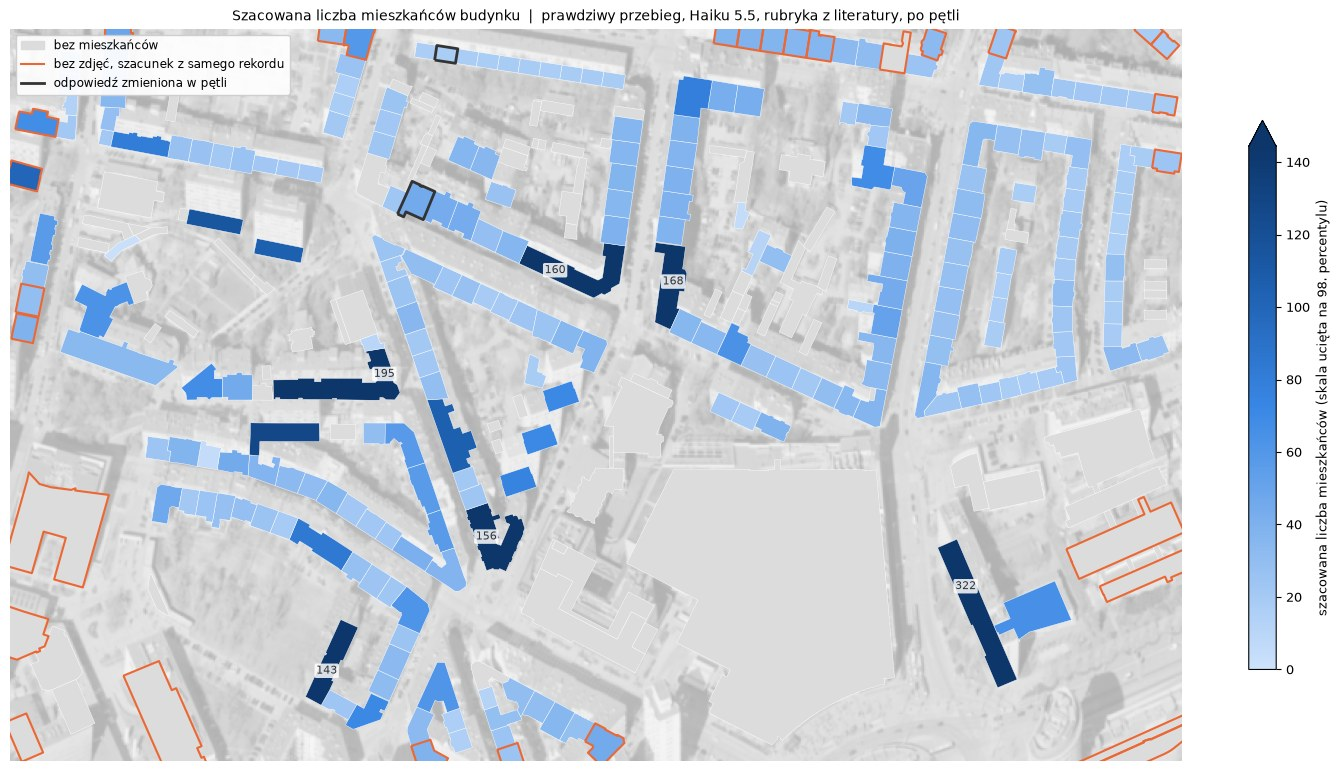

In [2]:
zamieszkane = wynik.mieszkancy[wynik.mieszkancy > 0]
bez_zdjec = wynik[wynik.liczba_widokow == 0]
display(Markdown(f"**Budynki: {len(wynik)}, błędy: {int(wynik.blad.notna().sum())}.** Zamieszkane: {len(zamieszkane)}, łącznie {tys(wynik.mieszkancy.sum())} os. "
                 f"(mediana {zamieszkane.median():.0f}, maksimum {zamieszkane.max():.0f} os. na budynek). Bez zdjęć, z samego rekordu: {len(bez_zdjec)} bud., {tys(bez_zdjec.mieszkancy.sum())} os."))

x0, y0, x1, y1 = zasieg().bounds
img, ext = czytaj("N", zasieg().bounds, 1.0)
tlo = 255 - (255 - img.mean(2)) * 0.35
mapa = bud.join(wynik[["mieszkancy", "liczba_widokow", "zmieniony"]])
fig, ax = plt.subplots(figsize=(15, 7.6), layout="constrained")
ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
mapa[mapa.mieszkancy.fillna(0) == 0].plot(ax=ax, color="#dcdcdc", edgecolor="white", linewidth=0.3)
mapa[mapa.mieszkancy > 0].plot(ax=ax, column="mieszkancy", cmap=NIEBIESKI, vmin=0, vmax=mapa.mieszkancy[mapa.mieszkancy > 0].quantile(0.98), edgecolor="white", linewidth=0.3,
                               legend=True, legend_kwds={"label": "szacowana liczba mieszkańców (skala ucięta na 98. percentylu)", "shrink": 0.75})
mapa[mapa.liczba_widokow == 0].boundary.plot(ax=ax, color=KOLORY[1], linewidth=1.5)
if wynik.zmieniony.any():
    mapa[mapa.zmieniony == True].boundary.plot(ax=ax, color=TUSZ, linewidth=2)  # noqa: E712
for _, b in mapa.nlargest(6, "mieszkancy").iterrows():
    p = b.geometry.representative_point()
    ax.text(p.x, p.y, f"{b.mieszkancy:.0f}", ha="center", va="center", fontsize=8, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.legend(handles=[Patch(color="#dcdcdc", label="bez mieszkańców"), Line2D([], [], color=KOLORY[1], lw=1.5, label="bez zdjęć, szacunek z samego rekordu"),
                   Line2D([], [], color=TUSZ, lw=2, label="odpowiedź zmieniona w pętli")], loc="upper left", fontsize=8.5, framealpha=0.92)
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Szacowana liczba mieszkańców budynku  |  prawdziwy przebieg, Haiku 5.5, rubryka z literatury, po pętli")
ax.set_axis_off()
plt.show()

## Czy sumy zgadzają się ze spisem?

To jedyna ocena liczby mieszkańców, jaką dziś mamy. Stan przed pętlą jest oceną niezależną. Po pętli jest kolista, bo agent widział te sumy.

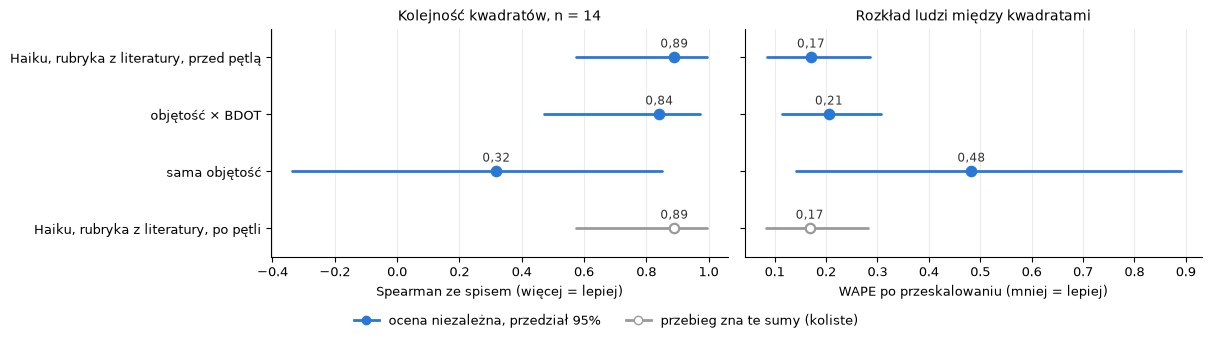

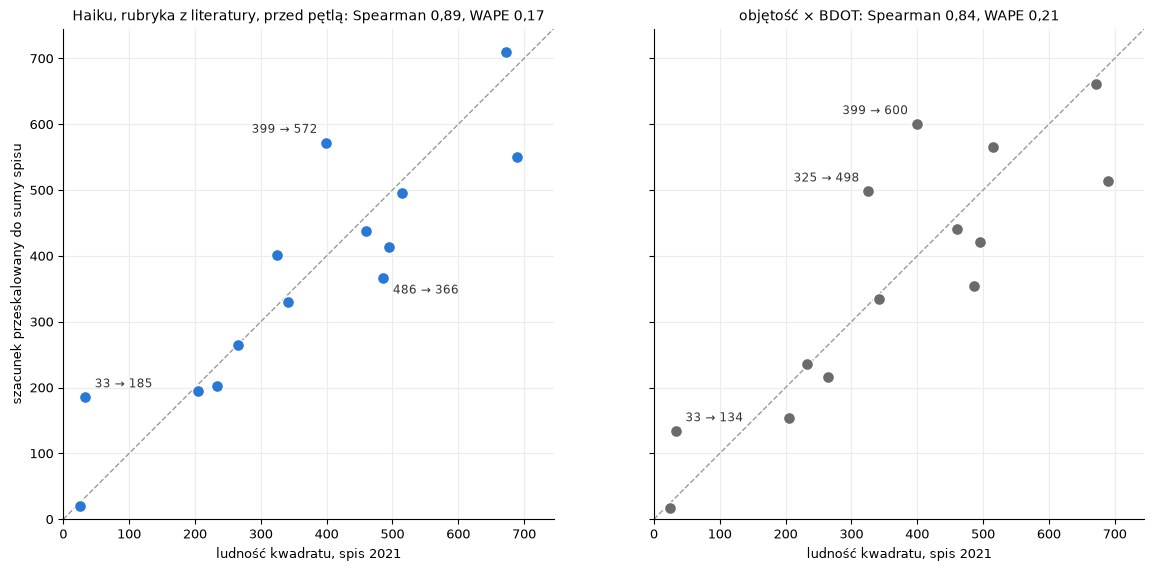

**Haiku a objętość × BDOT:** różnica Spearmana +0,05 [+0,00; +0,21], różnica WAPE -0,03 [-0,09; +0,03]. Oba przedziały obejmują zero, więc różnicy nie da się rozstrzygnąć.

**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje 33 os., baseline daje 134, a Haiku 185. Akademik ma setki miejsc, a spis liczy miejsce zamieszkania, nie pobyt, więc ten kwadrat mało mówi o trafności. Bez tego kwadratu różnica Spearmana to +0,06 [+0,00; +0,26], a WAPE -0,05 [-0,10; -0,00].

**Poziom jest niepewny:** na tych 14 kwadratach spis ma 5 145 os., a szacunek 5 828 os., czyli +13%. Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to 8 942 os., a po przeskalowaniu do spisu z tych kwadratów ok. 7 894 os.

In [3]:
PRED = wynik.reset_index()
BDOT, OBJETOSC = wczytaj("objetosc_bdot"), wczytaj("objetosc")
t = pd.DataFrame([ocena_kwadratow(PRED, miasto, kw, "mieszkancy_r0") | {"podpis": "Haiku, rubryka z literatury, przed pętlą", "kolista": False},
                  ocena_kwadratow(BDOT, miasto, kw) | {"podpis": "objętość × BDOT", "kolista": False},
                  ocena_kwadratow(OBJETOSC, miasto, kw) | {"podpis": "sama objętość", "kolista": False},
                  ocena_kwadratow(PRED, miasto, kw) | {"podpis": "Haiku, rubryka z literatury, po pętli", "kolista": True}])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True, layout="constrained")
for ax, miara, xlabel in ((a, "kw_spearman", "Spearman ze spisem (więcej = lepiej)"), (b, "kw_wape", "WAPE po przeskalowaniu (mniej = lepiej)")):
    for y, w in t.iterrows():
        kolor = SZARY if w.kolista else KOLORY[0]
        ax.plot([w[miara + "_lo"], w[miara + "_hi"]], [y, y], color=kolor, lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(w[miara], y, s=46, facecolor="white" if w.kolista else kolor, edgecolor=kolor, linewidth=1.6, zorder=3)
        ax.annotate(f"{w[miara]:.2f}".replace(".", ","), (w[miara], y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=TUSZ)
    ax.set_yticks(range(len(t)), t.podpis)
    ax.set_ylim(len(t) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
a.set_title(f"Kolejność kwadratów, n = {int(t.n_kwadratow.max())}")
b.set_title("Rozkład ludzi między kwadratami")
fig.legend(handles=[Line2D([], [], marker="o", color=KOLORY[0], lw=2, label="ocena niezależna, przedział 95%"),
                    Line2D([], [], marker="o", color=SZARY, markerfacecolor="white", lw=2, label="przebieg zna te sumy (koliste)")],
           loc="outside lower center", ncols=2, frameon=False)
plt.show()

fig, osie = plt.subplots(1, 2, figsize=(12, 5.6), sharex=True, sharey=True, layout="constrained")
for ax, (podpis, pred, kolumna, kolor) in zip(osie, [("Haiku, rubryka z literatury, przed pętlą", PRED, "mieszkancy_r0", KOLORY[0]), ("objętość × BDOT", BDOT, "mieszkancy", "#6b6b6b")]):
    suma, ref = sumy_kwadratow(pred, miasto, kw, kolumna)
    s = suma * ref.sum() / suma.sum()
    granica = 1.08 * max(s.max(), ref.max())
    ax.plot([0, granica], [0, granica], color=SZARY, ls="--", lw=1, zorder=1)
    ax.scatter(ref, s, s=75, color=kolor, edgecolor="white", linewidth=1, zorder=3)
    for kod_kwadratu in np.log((s + 1) / (ref + 1)).abs().nlargest(3).index:
        x, y = ref[kod_kwadratu], s[kod_kwadratu]
        w_lewo = y > x and x > 0.2 * granica  # etykieta przy osi szłaby poza wykres
        ax.annotate(f"{x:.0f} → {y:.0f}", (x, y), xytext=(-6, 7) if w_lewo else (7, 7 if y > x else -11), ha="right" if w_lewo else "left", textcoords="offset points", fontsize=8.5, color=TUSZ)
    w = t[t.podpis == podpis].iloc[0]
    ax.set(title=po_polsku(f"{podpis}: Spearman {w.kw_spearman:.2f}, WAPE {w.kw_wape:.2f}"), xlabel="ludność kwadratu, spis 2021", xlim=(0, granica), ylim=(0, granica), aspect="equal")
osie[0].set_ylabel("szacunek przeskalowany do sumy spisu")
plt.show()

a_, ref = sumy_kwadratow(PRED, miasto, kw, "mieszkancy_r0")
b_, _ = sumy_kwadratow(BDOT, miasto, kw)
d = porownaj_sumy(a_, b_, ref)
skalowany_a, skalowany_b = a_ * ref.sum() / a_.sum(), b_ * ref.sum() / b_.sum()
najgorszy = np.log((skalowany_b + 1) / (ref + 1)).abs().idxmax()  # kwadrat, w którym baseline myli się najbardziej
bez = porownaj_sumy(a_.drop(najgorszy), b_.drop(najgorszy), ref.drop(najgorszy))
display(Markdown(po_polsku(f"**Haiku a objętość × BDOT:** różnica Spearmana {d['d_spearman']:+.2f} [{d['d_spearman_lo']:+.2f}; {d['d_spearman_hi']:+.2f}], "
                           f"różnica WAPE {d['d_wape']:+.2f} [{d['d_wape_lo']:+.2f}; {d['d_wape_hi']:+.2f}]. Oba przedziały obejmują zero, więc różnicy nie da się rozstrzygnąć.\n\n"
                           f"**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje {ref[najgorszy]:.0f} os., baseline daje {skalowany_b[najgorszy]:.0f}, a Haiku {skalowany_a[najgorszy]:.0f}. "
                           f"Akademik ma setki miejsc, a spis liczy miejsce zamieszkania, nie pobyt, więc ten kwadrat mało mówi o trafności. Bez tego kwadratu różnica Spearmana to {bez['d_spearman']:+.2f} "
                           f"[{bez['d_spearman_lo']:+.2f}; {bez['d_spearman_hi']:+.2f}], a WAPE {bez['d_wape']:+.2f} [{bez['d_wape_lo']:+.2f}; {bez['d_wape_hi']:+.2f}].\n\n"
                           f"**Poziom jest niepewny:** na tych {d['n']} kwadratach spis ma {tys(ref.sum())} os., a szacunek {tys(a_.sum())} os., czyli {a_.sum() / ref.sum() - 1:+.0%}. "
                           f"Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to {tys(wynik.mieszkancy.sum())} os., "
                           f"a po przeskalowaniu do spisu z tych kwadratów ok. {tys(wynik.mieszkancy.sum() * ref.sum() / a_.sum())} os.")))

Gdzie szacunek rozjeżdża się ze spisem na mapie. Niebieski znaczy za mało, pomarańczowy za dużo, a etykiety to ludność ze spisu. Gruba ramka wokół kwadratu to flaga rozjazdu.

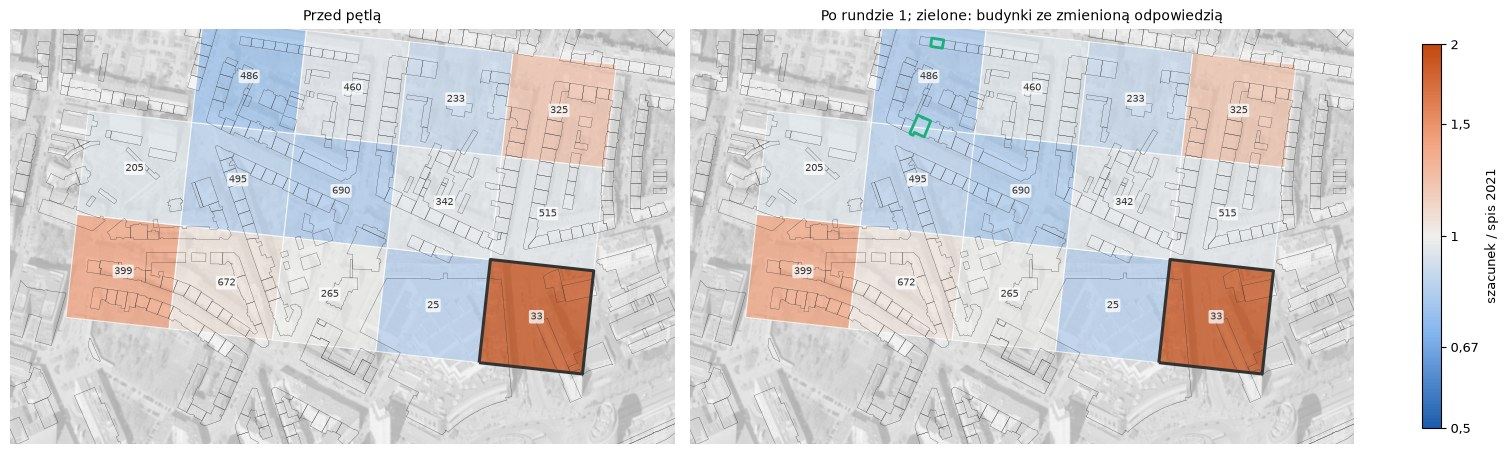

In [4]:
norma = LogNorm(0.5, 2)
zmienione = wynik.index[wynik.zmieniony]
fig, osie = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
for ax, runda in zip(osie, (0, int(bilanse.runda.max()))):
    r = bilanse[bilanse.runda == runda]
    ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
    kwadraty = kw.loc[r.index].assign(iloraz=r.iloraz)
    kwadraty.plot(ax=ax, column="iloraz", cmap=ROZJAZD, norm=norma, alpha=0.72, edgecolor="white", linewidth=0.8)
    if r.flaga.any():
        kwadraty[r.flaga].boundary.plot(ax=ax, color=TUSZ, linewidth=2.2)
    bud.boundary.plot(ax=ax, color=TUSZ, linewidth=0.2)
    if runda and len(zmienione):
        bud.loc[zmienione].boundary.plot(ax=ax, color=KOLORY[2], linewidth=2)
    for kod_kwadratu, w in r.iterrows():
        p = kw.geometry[kod_kwadratu].centroid
        if zasieg().contains(p):
            ax.text(p.x, p.y, f"{w.ludnosc:.0f}", ha="center", va="center", fontsize=7.5, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
    ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Przed pętlą" if runda == 0 else f"Po rundzie {runda}; zielone: budynki ze zmienioną odpowiedzią")
    ax.set_axis_off()
pasek = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=ROZJAZD), ax=osie, shrink=0.75, label="szacunek / spis 2021")
pasek.set_ticks([0.5, 0.67, 1, 1.5, 2], labels=["0,5", "0,67", "1", "1,5", "2"])
pasek.ax.minorticks_off()
plt.show()

## Kto gdzie mieszka

Typ budynku według świadka i rozkład szacunków. Kamienice dominują, bo tak wygląda ten fragment miasta; ten arkusz nie mówi nic o osiedlach domów jednorodzinnych.

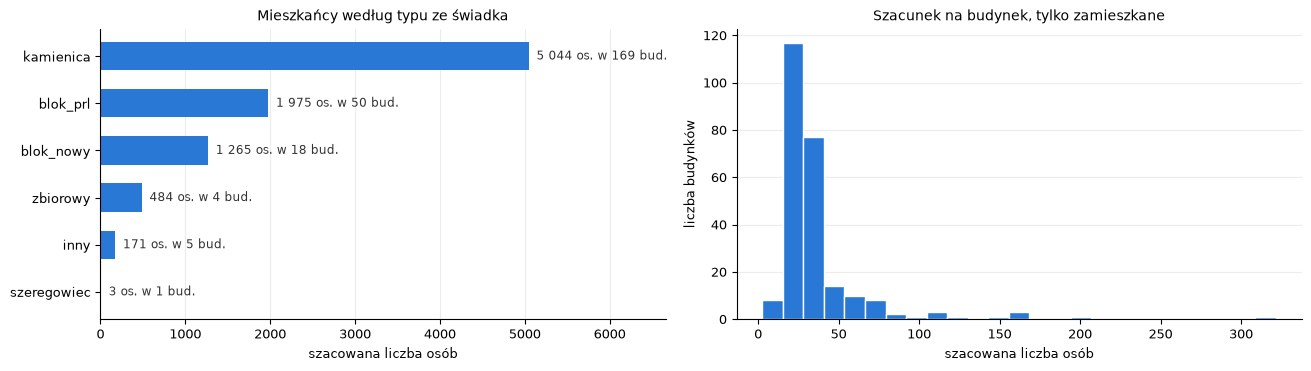

,funkcja,kond_bdot,pow_m2,typ,udzial_mieszkalny,pewnosc,mieszkancy
0,dom studencki,8.0,1467.0,zbiorowy,0.85,0.70,321.71
1,budynek wielorodzinny,6.0,1420.0,blok_nowy,0.85,0.50,195.35
2,budynek wielorodzinny,8.0,863.0,blok_prl,0.90,0.65,167.51
3,budynek wielorodzinny,6.0,1161.0,blok_nowy,0.85,0.60,159.74
4,budynek wielorodzinny,7.0,1032.0,kamienica,0.80,0.70,155.86
5,budynek wielorodzinny,8.0,738.0,blok_nowy,0.90,0.70,143.34
6,budynek wielorodzinny,8.0,659.0,blok_nowy,0.90,0.70,127.96
7,budynek wielorodzinny,12.0,392.0,blok_prl,0.90,0.85,114.29
8,budynek wielorodzinny,12.0,343.0,blok_prl,0.95,0.85,105.39
9,budynek wielorodzinny,6.0,765.0,blok_nowy,0.85,0.45,105.19


In [5]:
typy = wynik[wynik.mieszkancy > 0].groupby("typ").mieszkancy.agg(["sum", "size"]).sort_values("sum")
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained")
a.barh(typy.index, typy["sum"], color=KOLORY[0], height=0.6)
for y, (suma_typu, liczba) in enumerate(zip(typy["sum"], typy["size"])):
    a.text(suma_typu, y, f"  {tys(suma_typu)} os. w {liczba} bud.", va="center", fontsize=8.5, color=TUSZ)
a.set(title="Mieszkańcy według typu ze świadka", xlabel="szacowana liczba osób", xlim=(0, typy["sum"].max() * 1.32))
a.grid(axis="y", visible=False)
b.hist(wynik.mieszkancy[wynik.mieszkancy > 0], bins=25, color=KOLORY[0], edgecolor="white")
b.set(title="Szacunek na budynek, tylko zamieszkane", xlabel="szacowana liczba osób", ylabel="liczba budynków")
b.grid(axis="x", visible=False)
plt.show()

t = wynik.nlargest(10, "mieszkancy").join(bud[["funkcja"]]).join(bud.kondygnacje.rename("kond_bdot"))
t["pow_m2"] = bud.geometry.area.reindex(t.index).round()
t[["funkcja", "kond_bdot", "pow_m2", "typ", "udzial_mieszkalny", "pewnosc", "mieszkancy"]].round(2).reset_index(drop=True)

## Co zrobiła pętla

Wszystkie pytania agenta bilansującego i odpowiedzi świadka w tym przebiegu. Świadek widzi tu rekord BDOT10k, więc poprawki zgodne z rekordem nie są niezależnym potwierdzeniem.

In [6]:
kroki = ["**Flagi rozjazdu po rundach:** " + ", ".join(f"runda {int(n)}: {int(f)}" for n, f in bilanse.groupby("runda").flaga.sum().items()) +
         f". **Suma na arkuszu:** {tys(wynik.mieszkancy_r0.sum())} przed pętlą, {tys(wynik.mieszkancy.sum())} po niej."]
for w in dialog.itertuples():
    if w.rodzaj == "kwadrat":
        k = bilanse[bilanse.runda == w.runda - 1].loc[w.kod]
        kroki.append(f"**Agent, runda {w.runda:.0f}: kwadrat ze spisem {k.ludnosc:.0f} os. i szacunkiem {k.szacunek:.0f} os.** Diagnoza `{w.diagnoza}`.\n\n> {w.uzasadnienie}")
    elif w.rodzaj == "pytanie":
        b = bud.loc[w.budynek]
        kroki.append(f"**{b.funkcja}, {b.geometry.area:.0f} m².** Pytanie: *{w.pytanie}*\n\n> {w.odpowiedz}\n\n"
                     f"Zmiana: {w.zmiana or 'brak'}. Szacunek budynku: {w.mieszkancy_przed:.0f} -> {w.mieszkancy_po:.0f} os.")
display(Markdown("\n\n".join(kroki)))

**Flagi rozjazdu po rundach:** runda 0: 1, runda 1: 1. **Suma na arkuszu:** 8 921 przed pętlą, 8 942 po niej.

**Agent, runda 1: kwadrat ze spisem 33 os. i szacunkiem 185 os.** Diagnoza `rubryka`.

> Nadwyżka 185 względem 33 osób wynika głównie z domu studenckiego (1467 m², 8 kondygnacji), który po przyjęciu 31 m² na osobę dla klasy zbiorowy daje 284 osoby, czyli wartość zależną od przyjętej dla tej klasy normy, a nie od pojedynczego błędnego opisu.

**dom studencki, 1467 m².** Pytanie: *Opisujesz parter z apteką i handlem jako czynnik zmniejszający udział mieszkalny, a mimo to podajesz …. Na co zwróciłeś uwagę, oceniając udział części mieszkalnej tego budynku, np. na wejścia, okna parteru i wyższe kondygnacje?*

> Pytasz o udział mieszkalny: na elewacji wschodniej i zachodniej powtarza się siatka małych okien pokojowych na ośmiu kondygnacjach, co odpowiada pokojom domu studenckiego, a parter wyróżnia się tylko niższym, odmiennie wykończonym pasmem. Handel i apteka zajmują prawdopodobnie część parteru, więc na tle całego budynku ich udział jest niewielki, dlatego pozostaję przy 0,85 i obniżam pewność, bo nie widzę wnętrz ani podziału parteru.

Zmiana: brak. Szacunek budynku: 322 -> 322 os.

**budynek wielorodzinny, 31 m².** Pytanie: *Podajesz pewność … i piszesz, że budynek jest niski, ale nie wiesz, czy to blok. Czy na elewacji widocznej z widoku E widzisz cechy, które pozwalają odróżnić budynek wielorodzinny od usługowego lub gospodarczego? Jakie?*

> Na elewacji widocznej z widoku E widzę tylko niewielką ścianę z jednym lub dwoma małymi oknami przy dachu, bez regularnej siatki okien i balkonów typowej dla bloku. Wysokość 8,2 m, mała powierzchnia zabudowy 31 m² i obecność apteki przemawiają za niskim budynkiem usługowym z ewentualnym poddaszem, a nie za budynkiem wielorodzinnym, choć dane wejściowe są tu niepewne.

Zmiana: brak. Szacunek budynku: 0 -> 0 os.

**policja, 376 m².** Pytanie: *Przyjmujesz udział mieszkalny około …, ale opisujesz parter z niebieskim szyldem jako możliwy lokal usługowy lub instytucjonalny. Jakie elementy na parterze i na wyższych kondygnacjach, np. wejścia, tablice, okna i balkony, składają się na tę ocenę?*

> Na pytanie agenta: parter z niebieskim szyldem, witryną i wejściem schodowym wskazuje na lokal instytucjonalny (policja, zgodnie z BDOT), co obniża udział mieszkalny z 0,7 do około 0,75 mimo podobnego obrazu. Wyższe kondygnacje mają regularne okna, balkony z doniczkami i układ typowy dla mieszkań, więc przyjmuję, że przeważa zabudowa mieszkalna.

Zmiana: udzial_mieszkalny: 0.7 -> 0.75. Szacunek budynku: 43 -> 46 os.

**klasztor, 257 m².** Pytanie: *Opisujesz kościół z neogotyckimi oknami i rozetą, a rekord BDOT podaje klasztor. Czy w obrysie budynku widzisz elementy wskazujące na część mieszkalną, np. osobne wejścia, okna na wyższych poziomach lub inne funkcje niż sakralna?*

> Na zdjęciach nie widzę wyraźnych oznak części mieszkalnej, takich jak osobne wejścia czy regularne rzędy okien mieszkalnych; dominują neogotyckie okna i rozeta, co wskazuje na kościół. Boczne skrzydło z dwoma poziomami okien i lukarnami mogłoby być częścią klasztorną, ale nie daje to podstaw do zmiany typu, więc pozostaję przy usługach z obniżoną pewnością.

Zmiana: brak. Szacunek budynku: 0 -> 0 os.

**budynek wielorodzinny, 145 m².** Pytanie: *Twierdzisz, że budynek jest niemieszkalny, ale fasada z balkonami w widoku S może należeć do sąsiedniego bloku. Czy potrafisz wskazać, które ściany i wejścia należą do tego budynku, a które do sąsiedniego?*

> Poprzednia odpowiedź była błędna: w widoku S ściana północna w obrysie żółtym ma wyraźne rzędy okien i balkonów, a czerwony dach jest płaski, co pasuje do bloku mieszkalnego o pięciu kondygnacjach zgodnego z BDOT10k. Balkonowe fasady bocznych segmentów w tym samym widoku ocenię jako sąsiednie, bo leżą poza obrysem, więc nie wliczam ich do tego budynku.

Zmiana: typ: uslugi -> blok_prl; kondygnacje: 2 -> 5; udzial_mieszkalny: 0.0 -> 0.9. Szacunek budynku: 0 -> 18 os.

**garaż, 140 m².** Pytanie: *Opisujesz regularne okna i drzwi na fasadzie N, a rekord BDOT podaje garaż. Czy na tej fasadzie widzisz bramy garażowe lub wjazdy, czy raczej wejścia i okna mieszkalne? Co dokładnie decyduje o tej ocenie?*

> Na fasadzie N nie widać bram garażowych ani wjazdów, tylko regularne małe okna i jedne drzwi, a na fasadzie W rzędy małych okien. Decydują o tym rodzaj otworów w ścianie oraz wysokość 5,7 m, która odpowiada dwóm kondygnacjom, więc rekord BDOT o garażu uznaję za nieaktualny lub błędny, a poprzednią odpowiedź podtrzymuję.

Zmiana: brak. Szacunek budynku: 3 -> 3 os.

**obiekt handlowo-usługowy, 555 m².** Pytanie: *Rekord BDOT podaje stan nieczynny, a ty oceniasz budynek jako użytkowany na podstawie parkingu i stanu elewacji. Czy widzisz w obrębie budynku oznaki zamkniętych witryn, zasłoniętych okien lub braku oświetlenia, które mogłyby wskazywać na nieczynność?*

> Na zdjęciach nie widać zabitych desek, zasłoniętych okien ani zamkniętych witryn; szklana elewacja zachodnia i zielone drzwi północne wyglądają na zadbane, a dach jest czysty. Brak oświetlenia i stan wnętrz nie są jednak widoczne z ortofotomapy, więc rozbieżność z rekordem BDOT (nieczynny) pozostaje niepewna.

Zmiana: brak. Szacunek budynku: 0 -> 0 os.

**Agent, runda 2: kwadrat ze spisem 33 os. i szacunkiem 185 os.** Diagnoza `rubryka`.

> Niemal cały rozjazd (185 szacunku wobec 33 os. ze spisu) wynika z domu studenckiego 2881C5D6-690B-CEB0-E053-CC2BA8C034D4, którego szacunek 283 os. powstaje z wartości 31,0 m² na osobę przyjętej dla klasy zbiorowej, a opis świadka tego budynku jest spójny z rekordem BDOT10k.

## Jak to czytać

- **Dla pojedynczego budynku nie ma sprawdzenia.** Ocena dotyczy sum w kwadratach, więc liczba na konkretnym budynku to szacunek ze wzoru.
- **Nie widać przewagi nad baseline'em.** Przy 14 kwadratach przedziały różnicy sięgają zera. Ten przebieg nie pokazuje też, czy pomagają obrazy, bo porównuje cały system z objętością: do tego potrzebne są warianty bez obrazów i z obrazami innego budynku.
- **Zgodność z BDOT10k jest tu kolista.** Świadek widzi rekord, a jego odpowiedzi czasem wprost się na niego powołują.
- **Zamieszkanie zbiorowe to najsłabsza liczba rubryki.** 31 m² na miejsce to mediana z amerykańskich akademików, a klasa obejmuje też klasztory i domy opieki. Spis liczy miejsce zamieszkania, a nie pobyt, więc w kwadracie z akademikiem wyjdzie rozjazd nawet przy dobrym szacunku.
- **Pętla mało zmienia.** Dopytała o 7 budynków i zmieniła 2 opisy, w tym blok opisany wcześniej jako usługi.